## Context

This notebook accompanies User Guide section 2 (Architecture Overview).  It draws the six-layer stack and the three-gate flow side by side, then runs one tool call through the gateway end to end so the reader can correlate the diagram with a live `GatewayResult`.

In [1]:
# Phase 1B preamble: bootstrap runtime + load shared helpers
import sys
import os
import glob
import warnings
warnings.filterwarnings('ignore')
for _p in glob.glob(
        '/home/asudjianto/cluster/spark-venv/lib/python*/site-packages'):
    if _p not in sys.path:
        sys.path.insert(0, _p)
_REPO = os.path.expanduser('~/jupyterlab/kg-memory')
if _REPO not in sys.path:
    sys.path.insert(0, _REPO)

from user_guide_tutorials.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()  # idempotent; also stubs modeva if absent
from user_guide_tutorials.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


Device: cuda, CUDA available: True


### Concept: layers and gates are different axes

The governed agent has six conceptual **layers** that represent what the system knows: rules at the bottom, operations on top.  Layer 1 is the policy engine that encodes responsible-ML rules declaratively.  Layer 2 wraps those rules in formal finite-state contracts so they can be checked at every transition.  Layer 3 is the tool catalog with JSON schemas.  Layer 4 is the three-tier extraction surface that turns documents and tool outputs into triples.  Layer 5 is the geometric memory and reasoner.  Layer 6 is the governance stack: verifier, tracer, SPC release gates, compliance.

Orthogonal to layers are the three **gates**.  Every tool call passes through `GovernedToolGateway` which applies in order: schema validation, the policy engine, and a hard plausibility check that scores `(context, should_call, tool_name)` on $S^{m-1}$ and rejects calls whose geodesic distance exceeds $\theta_{\text{plaus}}$.  Layers describe knowledge; gates describe enforcement.  A given enforcement decision can read from any of the six layers.

The example below sets up a minimal pipeline and runs `load_dataset(name=iris)` through the gateway with the default `theta_plausibility=1.5`.  We expect the call to pass all three gates because no policy rule forbids it and the default plausibility scoring fails open when the relation triple is unknown.  We then verify each gate's verdict from `result.gate_results`.

In [ ]:
from knowlytix.harness.governance.session import SessionState
from knowlytix.harness.governance.governed_gateway import GovernedToolGateway
from knowlytix.harness.governance.tools import TOOL_DEFINITIONS

store = ug.load_ds_practices_store()
session = SessionState()
gateway = GovernedToolGateway(
    session=session,
    store=store,
    theta_plausibility=1.5,
    tool_schemas=TOOL_DEFINITIONS,
    device=str(DEVICE),
)
print('Gateway ready. theta_plausibility =',
      gateway.theta_plausibility)


In [3]:
# One tool call through all three gates
result = gateway.execute('load_dataset',
                         {'name': 'iris', 'builtin': 'iris'},
                         context='exploratory_data_analysis')
print(f"blocked = {result.blocked}")
print(f"reason  = {result.reason}")
print(f"gates   = {result.gate_results}")
print(f"plausibility score: {result.plausibility_score}")
print(f"latency: {result.execution_time_ms:.2f} ms")
print('---')
print(result.display)


blocked = False
reason  = All gates passed
gates   = {'schema': True, 'policy': True, 'plausibility': True, 'fault_injection': True}
plausibility score: None
latency: 4.36 ms
---
Loaded 'iris': 150 samples, 4 features, target='target', task=classification
  Train: 120, Test: 30


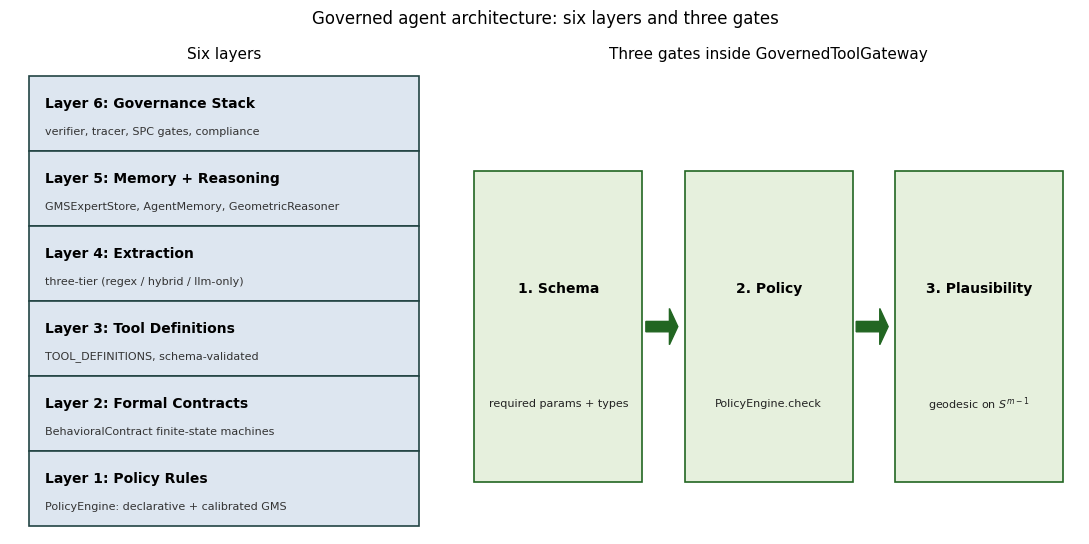

In [4]:
# Visualization: layers on the left, gates on the right
import matplotlib.pyplot as plt

fig, (ax_l, ax_r) = plt.subplots(
    1, 2, figsize=(11, 5.5),
    gridspec_kw={'width_ratios': [1.1, 1.6]},
)
h1.draw_six_layer_stack(ax_l)
h1.draw_three_gate_flow(ax_r)
fig.suptitle('Governed agent architecture: six layers and three gates',
             fontsize=12)
fig.tight_layout()
plt.show()


### Exercises

1. Re-run `gateway.execute` with `theta_plausibility=0.0` and observe which gate now blocks.  What does that say about fail-open vs fail-closed scoring when the (context, should_call, tool) triple is not in the store?
2. Construct an `args` dict that is missing the required `name` parameter and run it; the schema gate should block before the policy gate even fires.
3. Read `gateway._transcript[-1]` and identify the fields that would be useful for an offline auditor.

### What you should now be able to do

- Recite the six layers and what each one stores.
- Recite the three gates in order, schema, policy, plausibility.
- Execute a tool call and read its `GatewayResult` to   determine which gates fired and which blocked.
- Explain why layers and gates are orthogonal, not   hierarchical.

### Cross-references

- USER_GUIDE.md section 2 (Architecture Overview)
- `gms_agent_builder_ext/chapters/ch02.tex` for the   layered architecture in book form
- `governed_agent/governed_gateway.py:GovernedToolGateway.execute` (the three-gate implementation)

In [5]:
# Final assertion: minimal pipeline ran end to end.
assert result.blocked is False, \
    f'minimal pipeline blocked: {result.reason}'
print('OK: load_dataset passed schema, policy, '
      'and plausibility gates.')


OK: load_dataset passed schema, policy, and plausibility gates.
